# $\textbf{Phumlani Phakathi}$
# Observation Cosmology 

In [1]:
#Importing The necessary Python Modules
import numpy as np
import pylab as pl
from astropy.cosmology import WMAP7 as cosmo
import scipy.integrate as integrate
import scipy.special as special

In [2]:
cd Documents/2017\ MSc/Observational_\ Cosmology\ /Bruce_\ Basset/


[Errno 2] No such file or directory: 'Documents/2017 MSc/Observational_ Cosmology /Bruce_ Basset/'
/home/phumlani/Documents/2017 MSc/Observational_ Cosmology /Bruce_ Basset


# Question 2

0.196893457296


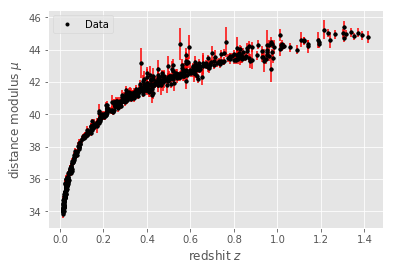

In [3]:
zz, mu, sigma = np.genfromtxt('supernova.txt', usecols = (1, 2, 3), unpack = True)

sig = np.sqrt((sigma)**2 + (0.12)**2) # supernova errors 
sig = np.array(sig)
print(sig[4])
pl.style.use('ggplot')
pl.xlabel('redshit $z$')
pl.ylabel('distance modulus $\mu$')
pl.errorbar(zz, mu, sig, fmt = 'k.', ecolor = 'r', capthick = 3)
pl.plot(zz, mu, 'k.', label = 'Data')
pl.legend(loc = 'best')
pl.show()

# Question 3

The Einstein-de Sitter Universe:
Using The Luminosity-redshift relation

By defining the dimensionless Hubble parameter and the Hubble constant, the relation between the different distances become apparent. 



$$\frac{H^{2}}{H_{0}^{2}} = \Omega_{m0} (1+z)^{3} + \Omega_{\Lambda_{0}}$$

$$ H = H_{0} [\sqrt{\Omega_{m0}} (1+z)^{\frac{3}{2}} + \sqrt{\Omega_{\Lambda_{0}}}]$$

The Hubble parameter at a given redshift is:

$$ H(z) = H_{0} [\sqrt{\Omega_{m0} (1+z)^{3} + \Omega_{\Lambda_{0}}}]$$

where $$ \Omega_{m0} = (1 - \Omega_{\Lambda_{0}})$$

Thus the Luminosity distance is given by:

$$ d_{L} = (1+z)  \chi$$

where $$\chi = \int_{0}^{z}\frac{c}{H(z')} dz'$$
is the comoving distance

c = speed of light.

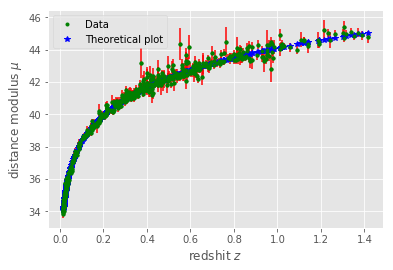

In [4]:
H0, c = 70, 3e+5
Om, Ode = 0.3, 0.7

#Cm = cosmo.comoving_distance(z)  
#dl = cosmo.luminosity_distance(z)

def H(z):
      return (H0*(np.sqrt(Om*((1+z)**3)+ Ode)))
    
I = []
for z in np.nditer(zz): 
    X,error = integrate.quad(lambda z: 1/H(z),0,z) 
    dl = (1+z)*c*X
    I.append(dl)

u = 5.0*np.log10(I) + 25.0

pl.style.use('ggplot')
pl.errorbar(zz, mu, sig, fmt = 'g.', ecolor= 'r', capthick=2)
pl.plot(zz, mu, 'g.', label = 'Data')
pl.plot(zz,u,'b*',label = 'Theoretical plot')

pl.xlabel('redshit $z$')
pl.ylabel('distance modulus $\mu$')
pl.legend(loc = 'best')
pl.show()


The above plot shows that the luminosity distance (dl) is better approximated at smaller redshifts, with the difference increasing with redshift.

# Question  4

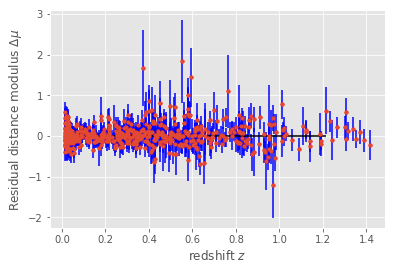

In [5]:
nu = mu - u #residual distance modulus

pl.style.use('ggplot')
pl.errorbar(zz,nu, sig, fmt = '.',ecolor = 'b', capthick = 2)
pl.hlines(0,zz[0],zz[-2], color = 'black')
pl.plot(zz, nu, 'r.')
pl.ylabel("Residual distance modulus $\Delta \mu$")
pl.xlabel("redshift $z$")
pl.show()

# Question 5

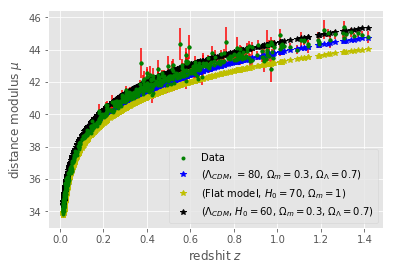

In [6]:
H01, Om1, Ode1 = 80, 0.3, 0.7 #lambdaCDM
H02, Om2, Ode2 = 80, 1.0, 0.0 #flat(no dark energy)
H03, Om3, Ode3 = 60, 0.3, 0.7 #standard_lambdaCDM


def f(z, H0, Om, Ode):
    return 1/(H0*(np.sqrt(Om*((1+z)**3)+ Ode)))

I1, I2, I3 = [], [], []

for z in np.nditer(zz): 
    X1,error = integrate.quad(f,0,z, args=(H01,Om1,Ode1))
    X2,error = integrate.quad(f,0,z, args=(H02,Om2,Ode2))
    X3,error = integrate.quad(f,0,z, args=(H03,Om3,Ode3))      
    dl1 = (1+z)*c*X1
    dl2 = (1+z)*c*X2
    dl3 = (1+z)*c*X3
    I1.append(dl1)
    I2.append(dl2)
    I3.append(dl3)
        
I1 = np.array(I1)   
I2 = np.array(I2)
I3 = np.array(I3)
    
u1 = 5.0*np.log10(I1) + 25.0
u2 = 5.0*np.log10(I2) + 25.0
u3 = 5.0*np.log10(I3) + 25.0


pl.style.use('ggplot')
pl.errorbar(zz, mu, sig, fmt = 'g.', ecolor= 'r', capthick=2)
pl.plot(zz, mu, 'g.', label = 'Data')
pl.plot(zz,u1,'b*',label = '($\Lambda_{CDM}$, $ = 80$, $\Omega_{m} = 0.3$, $\Omega_{\Lambda} = 0.7$)')
pl.plot(zz,u2,'y*',label = '(Flat model, $H_{0} = 70$, $\Omega_{m} = 1$)')
pl.plot(zz,u3,'k*',label = '($\Lambda_{CDM}$, $H_{0} = 60$, $\Omega_{m} = 0.3$, $\Omega_{\Lambda} = 0.7$)')

pl.xlabel('redshit $z$')
pl.ylabel('distance modulus $\mu$')
pl.legend(loc = 'best')
pl.show()

# Question 6

The 1st and 3rd plot are more or less the same standard model, with only a slightly different values of the hubble parameter. The 2nd plot (Flat model) shows a slower comoving separation, as a result of the model allowing a slower expansion rate.

The comoving distance $\chi$ increase with redshift at a fast rate untill its close to the decoupling redshitf (~1100).

# Question 7

In [7]:
def chi2(data,theory,error):
    X = float((((data-theory))/((error)))**2)
    return X

N = 500
accept, reject = 0,0
dmod0, dmd1 = [],[]
Xn, Xnt,thtn = [],[],[] 
 
H0  = np.random.uniform(40.0,100.0)
lamb  = np.random.uniform(0.0,1.0)
print(H0, lamb)

def muu(q):
    return 5.0*np.log10(q) + 25.0

def dlt(z):
    up = ((c/H0)*(1.0+z))
    below = (np.sqrt((1.0-lamb)*(1.0+z)**3 + lamb))
    r = up/below 
    return r

def dlnt(z):
    up = ((c/u1)*(1.0+z))
    below = (np.sqrt((1.0-u2)*(1.0+z)**3 + u2))
    r = up/below 
    return r

for i,j in enumerate(zz):
    innt1 = integrate.quad(dlt, 0, j)
    inn = innt1[0]
    dmod1 = muu(inn)
    dmod0.append(dmod1)

X1 = 0.0    
for i, j in enumerate(zz):
    X1 += chi2(mu[i], dmod0[i], sig[i])
Xn.append(X1)

for k in np.arange(0,N,1):
    if k % 10000 == 0:
        print(k)
    dteta1 = np.random.normal(0.0, 1.0)
    dteta2 = np.random.normal(0.0, 0.1)
    u1  = H0 + dteta1
    u2 = lamb + dteta2
    
    P = 1.00
    if H0 > 100 or lamb > 1.0:
        P == 0.0
    elif H0 < 0.0 or lamb < 0.0:
        P == 0.0
    else:
        P ==1.00
        
    while H0 > 100:
        H0 = np.random.normal(0.0,100.0)
    while H0 < 0:
        H0 = np.random.normal(0.0,100.0)
    while lamb > 1.00:
        lamb = np.random.normal(0.0,1.0)
    while lamb < 0.0:
        lamb = np.random.normal(0.0,1.0)
        
    Xtheta = 0.0
    for i, j in enumerate(zz):
        dist = integrate.quad(dlnt,0.0,j)
        innt = (dist[0])
        dmd2 = muu(innt)
        dmd1.append(dmd2)
        Xtheta += chi2(mu[i], dmd2, sig[i])
    
    Xnt.append(Xtheta)  
    dchi = (Xnt[k]-Xnt[k-1])
    R = (np.exp(-0.5*dchi))
    rr = np.random.uniform(0.0,1.0)
    
    if R > rr:
        Ho = u1
        lamb = u2
        accept += 1
        thtn.append([u1, u2])
        
    else:
        H0 = H0
        lamb = lamb
        reject += 1

print("Accepted =", accept, "|"  "Rejected = ", reject)
x = []
y = []
fp = open("data.txt", "w")
for r in thtn:
    fp.write("%f %f" %(r[0], r[1])) 
    x.append(r[0])
    y.append(r[1])
fp.close()

68.81225747020281 0.11425528310387378
0


/home/phumlani/Downloads/enter/lib/python3.6/site-packages/ipykernel/__main__.py:25: RuntimeWarning: invalid value encountered in sqrt
/home/phumlani/Downloads/enter/lib/python3.6/site-packages/scipy/integrate/quadpack.py:356: IntegrationWarning: The occurrence of roundoff error is detected, which prevents 
  the requested tolerance from being achieved.  The error may be 
  underestimated.
  warnings.warn(msg, IntegrationWarning)
/home/phumlani/Downloads/enter/lib/python3.6/site-packages/ipykernel/__main__.py:75: RuntimeWarning: overflow encountered in exp


Accepted = 246 |Rejected =  254


# Question 8

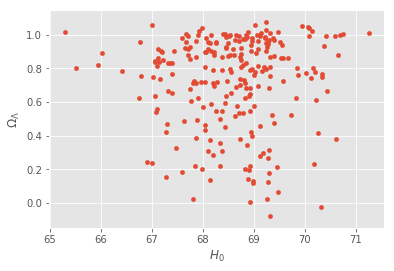

In [8]:
#Scatter plot
xx = np.array(x)
yy = np.array(y)

pl.scatter(xx, yy, s = 18)
pl.xlabel("$H_{0}$")
pl.ylabel("$\Omega_{\Lambda}$")
pl.show()

Since it is know that both $H_{0}$ and $\Omega_{\Lambda}$ have values between 0 and 100, the code initially draws two values from that interval.

Next i drew my step size for $H_{0}$ from a normal distribution centered at zero, with standard deviation of 1.00 which is $1\%$ of the total prior. The jump is therefore likely to occur in the positive direction. And for $\Omega_{\Lambda}$  , the jump step size is merely 0.01, which is also $1\%$ of the total prior.

The code then checks if the draw is outside the correct interval, if so, another draw occurs, until the next jump is within the preferred interval.

# Question 9

0.803237502588
0.803237502588
0.803237502588
0.803237502588


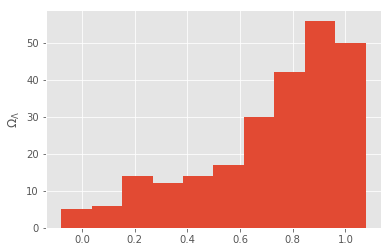

In [9]:
lamb_68 = np.percentile(lamb,16)
print (lamb_68)
omega_68 = np.percentile(lamb,84)
print (omega_68)

lamb_95 = np.percentile(lamb,2.5)
print (lamb_95)
omega_95 = np.percentile(lamb,97.5)
print (omega_95)


pl.hist(y)
pl.ylabel("$\Omega_{\Lambda}$")
pl.show()

Confidence limits plot for $\Omega_{DE}$